In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Load your dataset
df = pd.read_csv('donors.csv')  # Replace with your actual file path

print("=" * 50)
print("BASIC DATA OVERVIEW")
print("=" * 50)

# Shape and basic info
print(f"Dataset Shape: {df.shape}")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}\n")

# Column names and data types
print("Column Information:")
print(df.info())
print("\n" + "-"*50)

# First few rows
print("First 5 rows of the dataset:")
print(df.head())
print("\n" + "-"*50)

# Last few rows
print("Last 5 rows of the dataset:")
print(df.tail())

BASIC DATA OVERVIEW
Dataset Shape: (15000, 9)
Number of rows: 15000
Number of columns: 9

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   15000 non-null  object 
 1   age                       15000 non-null  int64  
 2   city                      15000 non-null  object 
 3   blood_type                15000 non-null  object 
 4   days_since_last_donation  15000 non-null  int64  
 5   total_notifications       15000 non-null  int64  
 6   times_donated             15000 non-null  int64  
 7   response_rate             15000 non-null  float64
 8   will_respond              15000 non-null  int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 1.0+ MB
None

--------------------------------------------------
First 5 rows of the dataset:
  user_id  age     city blood

In [4]:
print("=" * 50)
print("DATA QUALITY ANALYSIS")
print("=" * 50)

# Missing values
print("MISSING VALUES:")
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100
missing_info = pd.DataFrame({
    'Missing Count': missing_data,
    'Missing Percentage': missing_percent
})
print(missing_info[missing_info['Missing Count'] > 0])
print("\n")

# Duplicate rows
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates} ({duplicates/len(df)*100:.2f}%)")

# Data types summary
print("\nDATA TYPES SUMMARY:")
print(df.dtypes.value_counts())
print("\n")

# Numerical columns statistics
numerical_cols = df.select_dtypes(include=[np.number]).columns
print(f"Numerical columns ({len(numerical_cols)}): {list(numerical_cols)}")

# Categorical columns statistics
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
print(f"Categorical columns ({len(categorical_cols)}): {list(categorical_cols)}")

DATA QUALITY ANALYSIS
MISSING VALUES:
Empty DataFrame
Columns: [Missing Count, Missing Percentage]
Index: []


Number of duplicate rows: 0 (0.00%)

DATA TYPES SUMMARY:
int64      5
object     3
float64    1
Name: count, dtype: int64


Numerical columns (6): ['age', 'days_since_last_donation', 'total_notifications', 'times_donated', 'response_rate', 'will_respond']
Categorical columns (3): ['user_id', 'city', 'blood_type']


DETAILED FEATURE ANALYSIS
NUMERICAL FEATURES DESCRIPTION:
                age  days_since_last_donation  total_notifications  \
count  15000.000000              15000.000000          15000.00000   
mean      39.185667                219.878333             27.67200   
std       12.408212                233.700073             13.24519   
min       18.000000                 -1.000000              5.00000   
25%       28.000000                 59.000000             16.00000   
50%       39.000000                131.000000             28.00000   
75%       50.000000                298.000000             39.00000   
max       60.000000               1095.000000             50.00000   

       times_donated  response_rate  will_respond  
count   15000.000000   15000.000000  15000.000000  
mean        6.584067       0.238093      0.503333  
std         6.256469       0.186638      0.500006  
min         0.000000       0.000000      0.000000  
25%         2.000000       0.090000      0.000000  

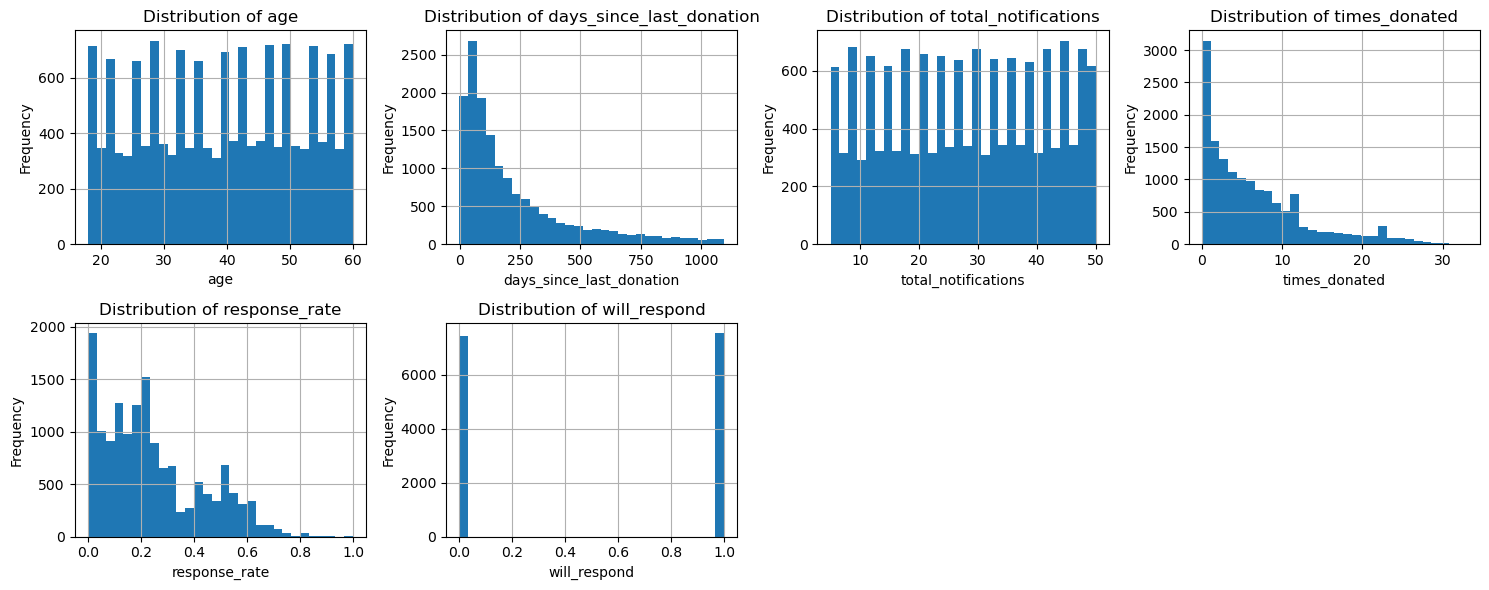

CATEGORICAL FEATURES ANALYSIS:

user_id:
  Unique values: 15000

city:
  Unique values: 10
  Value counts:
city
Lucknow      1555
Delhi        1545
Jaipur       1536
Mumbai       1525
Hyderabad    1510
Bangalore    1479
Ahmedabad    1478
Kolkata      1461
Pune         1456
Chennai      1455
Name: count, dtype: int64

blood_type:
  Unique values: 8
  Value counts:
blood_type
A+     1937
AB-    1921
O+     1895
B+     1891
O-     1890
A-     1864
B-     1847
AB+    1755
Name: count, dtype: int64


In [5]:
print("=" * 50)
print("DETAILED FEATURE ANALYSIS")
print("=" * 50)

# Numerical features description
if len(numerical_cols) > 0:
    print("NUMERICAL FEATURES DESCRIPTION:")
    print(df[numerical_cols].describe())
    print("\n")
    
    # Plot numerical features distributions
    if len(numerical_cols) > 0:
        n_cols = min(4, len(numerical_cols))
        n_rows = (len(numerical_cols) + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows*3))
        axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes
        
        for i, col in enumerate(numerical_cols):
            if i < len(axes):
                df[col].hist(bins=30, ax=axes[i])
                axes[i].set_title(f'Distribution of {col}')
                axes[i].set_xlabel(col)
                axes[i].set_ylabel('Frequency')
        
        # Hide empty subplots
        for i in range(len(numerical_cols), len(axes)):
            axes[i].set_visible(False)
            
        plt.tight_layout()
        plt.show()

# Categorical features analysis
if len(categorical_cols) > 0:
    print("CATEGORICAL FEATURES ANALYSIS:")
    for col in categorical_cols:
        if col != target_column:  # Skip target column
            print(f"\n{col}:")
            print(f"  Unique values: {df[col].nunique()}")
            if df[col].nunique() <= 15:  # Show value counts for columns with few unique values
                print(f"  Value counts:\n{df[col].value_counts().head(10)}")

In [4]:
!pip install xgboost

Access is denied.


In [1]:
# Save as preprocess_and_tune.py or paste into a Jupyter cell and run.
# Requirements: pandas, numpy, scikit-learn
# Optional but recommended: imbalanced-learn (pip install imbalanced-learn)
# If imbalanced-learn not available, the script will fallback to random oversampling.

import os
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.utils import resample

try:
    from imblearn.over_sampling import SMOTE
    IMBLEARN_AVAILABLE = True
except Exception:
    IMBLEARN_AVAILABLE = False

# ---------- USER CONFIG ----------
INPUT_CSV = "donors.csv"        # change path if needed
PROCESSED_CSV = "donors_processed.csv"
TRAIN_RESAMPLED_CSV = "donors_train_resampled.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.20
MAX_SELECTED_FEATURES = 30
# ---------- end config ----------

if not os.path.exists(INPUT_CSV):
    raise FileNotFoundError(f"{INPUT_CSV} not found; place the file in the same folder or update INPUT_CSV path.")

df = pd.read_csv(INPUT_CSV)
print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())

# Try to detect target column (common names); otherwise assume last column
target_candidates = ['target','label','response','donated','donor','y','Outcome','Class','Target']
target_col = None
for c in target_candidates:
    if c in df.columns:
        target_col = c
        break
if target_col is None:
    target_col = df.columns[-1]
print("Using target column:", target_col)
y = df[target_col]
print("Target value counts:\n", y.value_counts())

# Features
X = df.drop(columns=[target_col]).copy()

# Separate numeric and categorical
num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object','category','bool']).columns.tolist()
print("Numeric cols:", num_cols)
print("Categorical cols:", cat_cols)

# ---------- Preprocessing ----------
# Numeric: median impute + standardize
num_imp = SimpleImputer(strategy='median')
X_num = pd.DataFrame(num_imp.fit_transform(X[num_cols]), columns=num_cols)
scaler = StandardScaler()
X_num_scaled = pd.DataFrame(scaler.fit_transform(X_num), columns=num_cols)

# Categorical:
# - low-cardinality (<=10 unique) -> one-hot (drop_first True)
# - high-cardinality (>10) -> frequency encoding (probability / relative frequency)
low_card = [c for c in cat_cols if X[c].nunique() <= 10]
high_card = [c for c in cat_cols if X[c].nunique() > 10]

if low_card:
    X_low = pd.get_dummies(X[low_card].fillna('MISSING'), drop_first=True)
else:
    X_low = pd.DataFrame(index=X.index)

X_high = pd.DataFrame(index=X.index)
for c in high_card:
    freq = X[c].fillna('MISSING').value_counts(normalize=True)
    X_high[c + "_freq_enc"] = X[c].fillna('MISSING').map(freq)

X_processed = pd.concat([X_num_scaled.reset_index(drop=True),
                         X_low.reset_index(drop=True),
                         X_high.reset_index(drop=True)], axis=1).fillna(0)

# Save processed dataset (useful for re-training / inspection)
processed_df = pd.concat([X_processed, y.reset_index(drop=True)], axis=1)
processed_df.to_csv(PROCESSED_CSV, index=False)
print("Saved processed dataset to:", PROCESSED_CSV)
print("Processed dataset shape:", X_processed.shape)

# ---------- Train/Test split ----------
X_train, X_test, y_train, y_test = train_test_split(X_processed, y,
                                                    test_size=TEST_SIZE,
                                                    random_state=RANDOM_STATE,
                                                    stratify=y)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

# ---------- Handle class imbalance ----------
if IMBLEARN_AVAILABLE:
    print("Using SMOTE for balancing (imblearn installed).")
    sm = SMOTE(random_state=RANDOM_STATE)
    X_train_res, y_train_res = sm.fit_resample(X_train, y_train)
else:
    print("imblearn not available — using random oversampling of minority class.")
    train_concat = pd.concat([X_train, y_train.reset_index(drop=True)], axis=1)
    maj_class = y_train.value_counts().idxmax()
    min_class = y_train.value_counts().idxmin()
    maj = train_concat[train_concat[target_col] == maj_class]
    minr = train_concat[train_concat[target_col] == min_class]
    if len(minr) == 0:
        X_train_res, y_train_res = X_train, y_train
    else:
        minr_up = resample(minr, replace=True, n_samples=len(maj), random_state=RANDOM_STATE)
        train_res = pd.concat([maj, minr_up])
        X_train_res = train_res.drop(columns=[target_col]).fillna(0)
        y_train_res = train_res[target_col]

# Save resampled train set
pd.concat([X_train_res.reset_index(drop=True), y_train_res.reset_index(drop=True)], axis=1).to_csv(TRAIN_RESAMPLED_CSV, index=False)
print("Saved resampled training set to:", TRAIN_RESAMPLED_CSV)

# ---------- Feature selection ----------
k = min(MAX_SELECTED_FEATURES, X_train_res.shape[1])
selector = SelectKBest(score_func=mutual_info_classif, k=k)
selector.fit(X_train_res, y_train_res)
selected_mask = selector.get_support()
selected_features = X_train_res.columns[selected_mask].tolist()
print("Selected top features (k={}):".format(k), selected_features)

X_train_sel = selector.transform(X_train_res)
X_test_sel = selector.transform(X_test.fillna(0))

# ---------- Hyperparameter tuning (Logistic Regression) ----------
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'class_weight': [None, 'balanced']
}
log = LogisticRegression(max_iter=2000, solver='lbfgs', random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(log, param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_sel, y_train_res)

best = grid.best_estimator_
print("Best params:", grid.best_params_)

# ---------- Evaluation ----------
y_pred = best.predict(X_test_sel)
acc = accuracy_score(y_test, y_pred)
print("Test accuracy:", acc)
print("Classification report:\n", classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

# ---------- Save best model artifacts (optional) ----------
# You can pickle the trained model or save selected feature names for later use.
import joblib
joblib.dump(best, "best_logistic_model.joblib")
pd.Series(selected_features).to_csv("selected_features.csv", index=False)
print("Saved best model to best_logistic_model.joblib and selected_features.csv")


Original shape: (15000, 9)
Columns: ['user_id', 'age', 'city', 'blood_type', 'days_since_last_donation', 'total_notifications', 'times_donated', 'response_rate', 'will_respond']
Using target column: will_respond
Target value counts:
 will_respond
1    7550
0    7450
Name: count, dtype: int64
Numeric cols: ['age', 'days_since_last_donation', 'total_notifications', 'times_donated', 'response_rate']
Categorical cols: ['user_id', 'city', 'blood_type']
Saved processed dataset to: donors_processed.csv
Processed dataset shape: (15000, 22)
Train shape: (12000, 22) Test shape: (3000, 22)
imblearn not available — using random oversampling of minority class.
Saved resampled training set to: donors_train_resampled.csv
Selected top features (k=22): ['age', 'days_since_last_donation', 'total_notifications', 'times_donated', 'response_rate', 'city_Bangalore', 'city_Chennai', 'city_Delhi', 'city_Hyderabad', 'city_Jaipur', 'city_Kolkata', 'city_Lucknow', 'city_Mumbai', 'city_Pune', 'blood_type_A-', 'bl